# SVM phân loại video ngôn ngữ ký hiệu trên đặc trưng EfficientNet-B0

**BTL Khai phá dữ liệu – HK261.**

Mỗi video đã được notebook `extract-features` biến thành 16 vector 1.280 chiều (một vector mỗi khung). SVM cần **một** vector cho mỗi video, nên notebook này:

1. gộp 16 vector theo 3 cách (F1 trung bình, F2 trung bình + độ lệch chuẩn, F3 trung bình 4 đoạn);
2. chọn cấu hình tốt nhất của `StandardScaler → PCA → SVM` bằng cross-validation 4 lần trên fold 1–4, tiêu chí **Macro F1**;
3. đánh giá **một lần** trên fold 0 (555 video chưa dùng để chọn tham số);
4. huấn luyện lại trên cả 2.772 video và ghi file nộp AIChallenge.

**wandb:** có `WANDB_API_KEY` thì log online, không có thì chạy offline; log nằm ở `wandb/offline-run-*` trong thư mục output.

In [1]:
import os, sys, json, time, shutil, tempfile, warnings, unicodedata, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)
SEED = 42
VAL_FOLD = 0
QUICK = os.environ.get('QUICK', '0') == '1'          
N_JOBS = int(os.environ.get('N_JOBS', '-1'))
WANDB_PROJECT = 'dm-sign-language'

ON_KAGGLE = Path('/kaggle/input').exists()
if ON_KAGGLE:
    ROOT = Path('/kaggle')
    SEARCH_ROOTS, OUT = [ROOT / 'input'], ROOT / 'working'
else:                                                 
    ROOT = Path(os.environ.get('PROJECT_ROOT', Path.cwd().parents[1]))
    SEARCH_ROOTS, OUT = [ROOT / 'models' / 'features'], ROOT / 'models' / 'svm' / 'output'
if os.environ.get('FEAT_DIR'):
    SEARCH_ROOTS = [Path(os.environ['FEAT_DIR'])]
OUT = Path(os.environ.get('OUT_DIR', OUT))
OUT.mkdir(parents=True, exist_ok=True)


def find_file(name):
    for root in SEARCH_ROOTS:
        hits = sorted(root.rglob(name)) if root.exists() else []
        if hits:
            return hits[0]
    raise FileNotFoundError(f'Không tìm thấy {name} trong {SEARCH_ROOTS} – đã gắn output của extract-features chưa?')


def rel(path):
    return path.relative_to(ROOT) if path.is_relative_to(ROOT) else path


FEAT_DIR = find_file('feat_train.npy').parent
print('Đặc trưng:', rel(FEAT_DIR))
print('Output   :', rel(OUT), '| QUICK =', QUICK)

Đặc trưng: models/features
Output   : models/svm/output | QUICK = False


In [2]:
# wandb
try:
    import wandb
except ImportError:
    wandb = None
api_key = os.environ.get('WANDB_API_KEY')
if ON_KAGGLE and not api_key:
    try:
        from kaggle_secrets import UserSecretsClient
        api_key = UserSecretsClient().get_secret('WANDB_API_KEY')
    except Exception:
        api_key = None
WANDB_MODE = 'online' if api_key else 'offline'
run = None
if wandb is not None:
    os.environ['WANDB_DIR'] = str(OUT)
    os.environ['WANDB_SILENT'] = 'true'
    if api_key:
        wandb.login(key=api_key)
    run = wandb.init(project=WANDB_PROJECT, name='svm-gridsearch', job_type='svm', mode=WANDB_MODE,
                     config={'model': 'svm', 'backbone': 'efficientnet_b0', 'T': 16, 'seed': SEED,
                             'val_fold': VAL_FOLD, 'quick': QUICK})
print('wandb:', WANDB_MODE if wandb is not None else 'chưa cài – bỏ qua')

wandb: offline


## 1. Đọc đặc trưng và nhãn

`feat_train.npy` có thứ tự dòng khớp `manifest_clean.csv` (chép kèm trong output của `extract-features`), nên nhãn và fold lấy từ manifest. Tên lớp hiển thị dùng dạng NFC trong manifest; tên ghi vào file nộp lấy từ `label_names.json` (dạng NFD, đúng như `label_mapping.pkl`).

In [3]:
F_train = np.load(FEAT_DIR / 'feat_train.npy').astype(np.float32)        # (N, 16, 1280)
manifest = pd.read_csv(FEAT_DIR / 'manifest_clean.csv')
test_manifest = pd.read_csv(FEAT_DIR / 'test_manifest.csv')
label_names = json.load(open(FEAT_DIR / 'label_names.json', encoding='utf-8'))   # NFD, theo chỉ số 0..99
display_names = manifest.drop_duplicates('label_idx').set_index('label_idx').cls.sort_index().tolist()

y = manifest.label_idx.values
fold = manifest.fold.values
assert len(F_train) == len(manifest), (F_train.shape, len(manifest))
assert len(label_names) == 100 and len(display_names) == 100
cv_mask, val_mask = fold != VAL_FOLD, fold == VAL_FOLD
print('Đặc trưng train:', F_train.shape, '| train (fold 1–4):', cv_mask.sum(), '| validation (fold 0):', val_mask.sum())
print('Số lớp trong fold 1–4:', len(np.unique(y[cv_mask])), '| trong fold 0:', len(np.unique(y[val_mask])))

Đặc trưng train: (2772, 16, 1280) | train (fold 1–4): 2217 | validation (fold 0): 555
Số lớp trong fold 1–4: 100 | trong fold 0: 100


## 2. Ba cách gộp 16 khung thành một vector

| Mã | Cách gộp | Số chiều | Giữ thông tin gì |
|---|---|---|---|
| F1 | Trung bình 16 khung | 1.280 | Tư thế trung bình, mất thứ tự |
| F2 | Trung bình + độ lệch chuẩn | 2.560 | Thêm mức độ thay đổi qua thời gian |
| F3 | Trung bình của 4 đoạn liên tiếp (khung 1–4, 5–8, 9–12, 13–16), nối lại | 5.120 | Thứ tự thời gian ở mức thô: đầu, giữa, cuối |

In [4]:
def pool(F, kind):
    if kind == 'F1':
        return F.mean(1)
    if kind == 'F2':
        return np.concatenate([F.mean(1), F.std(1)], axis=1)
    if kind == 'F3':
        return np.concatenate([seg.mean(1) for seg in np.array_split(F, 4, axis=1)], axis=1)
    raise ValueError(kind)


FEATURES = ['F1', 'F3'] if QUICK else ['F1', 'F2', 'F3']
X = {k: pool(F_train, k) for k in FEATURES}
for k, v in X.items():
    print(k, v.shape)

F1 (2772, 1280)
F2 (2772, 2560)
F3 (2772, 5120)


## 3. Grid search bằng cross-validation 4 lần trên fold 1–4

Pipeline `StandardScaler → PCA → SVM` được fit lại từ đầu ở mỗi lần chia, nên chuẩn hoá và PCA chỉ học từ phần train của lần chia đó (không rò rỉ sang phần kiểm tra). `PredefinedSplit` dùng đúng cột `fold` của manifest. Pipeline có bộ nhớ đệm: PCA của một lần chia được tính một lần rồi dùng lại cho mọi giá trị C, γ.

| Thành phần | Giá trị thử |
|---|---|
| PCA | giữ 95% phương sai; 256 thành phần |
| SVM tuyến tính (`LinearSVC`, một-đấu-phần-còn-lại) | C ∈ {0,001; 0,01} |
| SVM RBF (`SVC`, một-đấu-một) | C ∈ {1; 10}, γ ∈ {`scale`; 0,001} |

Mọi cấu hình dùng `class_weight='balanced'` (trọng số w_c = N / (K·n_c), tính lại trên phần train của mỗi lần chia).

In [5]:
if QUICK:
    PCA_OPTS = [128]
    grid = [{'pca__n_components': PCA_OPTS, 'svm': [LinearSVC(class_weight='balanced', max_iter=5000, random_state=SEED)],
             'svm__C': [0.01]},
            {'pca__n_components': PCA_OPTS, 'svm': [SVC(kernel='rbf', class_weight='balanced')],
             'svm__C': [10], 'svm__gamma': ['scale']}]
else:
    PCA_OPTS = [0.95, 256]
    grid = [{'pca__n_components': PCA_OPTS, 'svm': [LinearSVC(class_weight='balanced', max_iter=5000, random_state=SEED)],
             'svm__C': [0.001, 0.01]},
            {'pca__n_components': PCA_OPTS, 'svm': [SVC(kernel='rbf', class_weight='balanced')],
             'svm__C': [1, 10], 'svm__gamma': ['scale', 1e-3]}]

cv = PredefinedSplit(fold[cv_mask] - 1)            # fold 1..4 -> 0..3
rows, t_all = [], time.time()
for k in FEATURES:
    cache = tempfile.mkdtemp()
    pipe = Pipeline([('scaler', StandardScaler()), ('pca', PCA(random_state=SEED)), ('svm', SVC())], memory=cache)
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, scoring='f1_macro', cv=cv, n_jobs=N_JOBS, refit=False)
    gs.fit(X[k][cv_mask], y[cv_mask])
    res = gs.cv_results_
    for i, p in enumerate(res['params']):
        is_rbf = isinstance(p['svm'], SVC)
        rows.append({'feature': k, 'kernel': 'rbf' if is_rbf else 'linear', 'pca': str(p['pca__n_components']),
                     'C': p['svm__C'], 'gamma': str(p.get('svm__gamma', '-')),
                     'cv_f1_mean': res['mean_test_score'][i], 'cv_f1_std': res['std_test_score'][i],
                     'fit_seconds': res['mean_fit_time'][i], '_params': p})
    shutil.rmtree(cache, ignore_errors=True)
    print(f'{k}: {len(res["params"])} cấu hình x 4 lần chia trong {time.time() - t0:.0f}s, '
          f'tốt nhất cv F1 = {res["mean_test_score"].max():.4f}')

cv_df = pd.DataFrame(rows).sort_values('cv_f1_mean', ascending=False).reset_index(drop=True)
print(f'Tổng thời gian grid search: {time.time() - t_all:.0f}s')
cv_df.drop(columns='_params').head(10)

F1: 12 cấu hình x 4 lần chia trong 19s, tốt nhất cv F1 = 0.6255
F2: 12 cấu hình x 4 lần chia trong 37s, tốt nhất cv F1 = 0.6792
F3: 12 cấu hình x 4 lần chia trong 55s, tốt nhất cv F1 = 0.6344
Tổng thời gian grid search: 111s


,feature,kernel,pca,C,gamma,cv_f1_mean,cv_f1_std,fit_seconds
0,F2,linear,0.95,0.010,-,0.679191,0.007825,35.275368
1,F2,linear,0.95,0.001,-,0.634695,0.015175,26.181503
2,F3,linear,0.95,0.010,-,0.634355,0.011310,54.926281
3,F2,rbf,0.95,10.000,scale,0.628774,0.016554,1.161853
4,F1,rbf,256,10.000,scale,0.625469,0.012590,0.554509
5,F1,rbf,0.95,10.000,scale,0.625450,0.011372,0.509597
6,F1,rbf,0.95,10.000,0.001,0.624366,0.012892,0.518613
7,F2,linear,256,0.010,-,0.623985,0.009053,10.670399
8,F1,rbf,256,10.000,0.001,0.623822,0.011210,0.539553
9,F2,rbf,256,10.000,scale,0.621950,0.016112,0.701589


## 4. So sánh các cấu hình

Hình trái: Macro F1 cross-validation tốt nhất của mỗi cách gộp và mỗi kernel, cho biết giữ thông tin thời gian (F3) có giúp hơn trung bình đơn thuần (F1) không. 
Hình phải: với cách gộp tốt nhất, Macro F1 theo C (lấy cấu hình tốt nhất của các tham số còn lại).

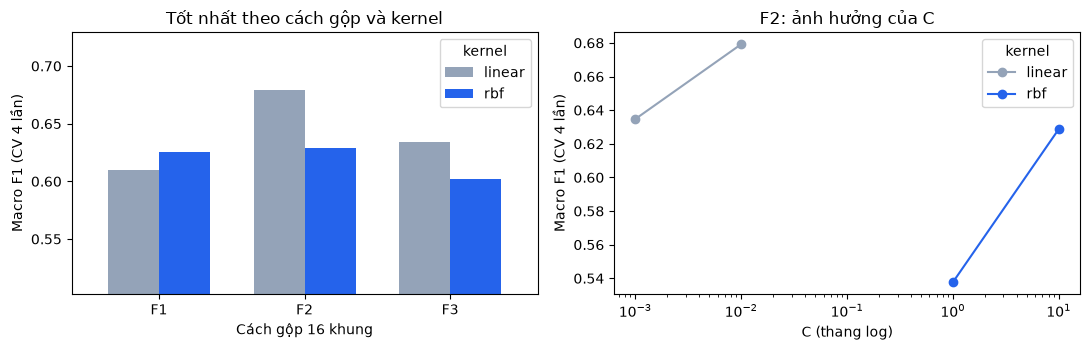

kernel   linear     rbf
feature                
F1       0.6097  0.6255
F2       0.6792  0.6288
F3       0.6344  0.6023


In [6]:
best_by = cv_df.groupby(['feature', 'kernel']).cv_f1_mean.max().unstack('kernel').reindex(FEATURES)
best_feat = cv_df.feature.iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
best_by.plot.bar(ax=axes[0], rot=0, color={'linear': '#94a3b8', 'rbf': '#2563eb'}, width=0.7)
axes[0].set_ylabel('Macro F1 (CV 4 lần)'); axes[0].set_xlabel('Cách gộp 16 khung')
axes[0].set_title('Tốt nhất theo cách gộp và kernel'); axes[0].legend(title='kernel')
axes[0].set_ylim(max(0, best_by.min().min() - 0.1), min(1, best_by.max().max() + 0.05))
sub = cv_df[cv_df.feature == best_feat]
for kern, color in [('linear', '#94a3b8'), ('rbf', '#2563eb')]:
    s = sub[sub.kernel == kern].groupby('C').cv_f1_mean.max()
    if len(s):
        axes[1].plot(s.index, s.values, 'o-', color=color, label=kern)
axes[1].set_xscale('log'); axes[1].set_xlabel('C (thang log)'); axes[1].set_ylabel('Macro F1 (CV 4 lần)')
axes[1].set_title(f'{best_feat}: ảnh hưởng của C'); axes[1].legend(title='kernel')
fig.tight_layout(); fig.savefig(OUT / 'svm_gridsearch.png', dpi=150, bbox_inches='tight'); plt.show()
print(best_by.round(4))

## 5. Đánh giá một lần trên fold 0

Cấu hình tốt nhất được huấn luyện trên fold 1–4 và dự đoán 555 video fold 0. Đây là con số báo cáo, so sánh được với CNN-LSTM và ViT vì cùng fold 0.

In [7]:
best = cv_df.iloc[0]
best_params = best['_params']
best_desc = (f"{best.feature}, PCA={best.pca}, {best.kernel}, C={best.C}"
             + (f", gamma={best.gamma}" if best.kernel == 'rbf' else ''))
print('Cấu hình tốt nhất:', best_desc, f'| CV F1 = {best.cv_f1_mean:.4f} ± {best.cv_f1_std:.4f}')


def make_pipeline(params):
    pipe = Pipeline([('scaler', StandardScaler()), ('pca', PCA(random_state=SEED)), ('svm', SVC())])
    return clone(pipe).set_params(**{k: (clone(v) if k == 'svm' else v) for k, v in params.items()})


t0 = time.time()
val_pipe = make_pipeline(best_params).fit(X[best.feature][cv_mask], y[cv_mask])
pred_val = val_pipe.predict(X[best.feature][val_mask])
y_val = y[val_mask]
val_acc, val_f1 = accuracy_score(y_val, pred_val), f1_score(y_val, pred_val, average='macro')
print(f'Fold 0: accuracy = {val_acc:.4f} | Macro F1 = {val_f1:.4f} | {time.time() - t0:.0f}s')

rep = classification_report(y_val, pred_val, labels=range(100), target_names=display_names,
                            output_dict=True, zero_division=0)
per_class = (pd.DataFrame(rep).T.iloc[:100].rename_axis('class').reset_index()
             .assign(label_idx=range(100)))[['label_idx', 'class', 'precision', 'recall', 'f1-score', 'support']]
per_class.to_csv(OUT / 'fold0_report.csv', index=False)
print('\n10 lớp có F1 thấp nhất trên fold 0 (mỗi lớp chỉ 1–10 video nên chỉ để tham khảo):')
print(per_class.sort_values(['f1-score', 'support']).head(10).to_string(index=False))

cm = confusion_matrix(y_val, pred_val, labels=range(100))
np.fill_diagonal(cm, 0)
pairs = [(display_names[i], display_names[j], cm[i, j]) for i, j in zip(*np.nonzero(cm))]
pairs = sorted(pairs, key=lambda t: -t[2])[:10]
print('\nCác cặp hay nhầm nhất (nhãn thật -> dự đoán, số video):')
for a, b, n in pairs:
    print(f'  {a} -> {b}: {n}')

Cấu hình tốt nhất: F2, PCA=0.95, linear, C=0.01 | CV F1 = 0.6792 ± 0.0078
Fold 0: accuracy = 0.8090 | Macro F1 = 0.6823 | 22s

10 lớp có F1 thấp nhất trên fold 0 (mỗi lớp chỉ 1–10 video nên chỉ để tham khảo):
 label_idx      class  precision  recall  f1-score  support
         5    Ban đêm        0.0     0.0       0.0      1.0
         6    Bàn tay        0.0     0.0       0.0      1.0
        10  Bệnh nhân        0.0     0.0       0.0      1.0
        18        Cần        0.0     0.0       0.0      1.0
        30     Cơ thể        0.0     0.0       0.0      1.0
        37         Ho        0.0     0.0       0.0      1.0
        40   Học sinh        0.0     0.0       0.0      1.0
        44 Khẩu trang        0.0     0.0       0.0      1.0
        48    Lo lắng        0.0     0.0       0.0      1.0
        54   Ngón tay        0.0     0.0       0.0      1.0

Các cặp hay nhầm nhất (nhãn thật -> dự đoán, số video):
  Ăn -> Khóc: 3
  Họ -> Con gấu: 3
  Ban ngày -> Chiều: 2
  Bạn thân -> Ch

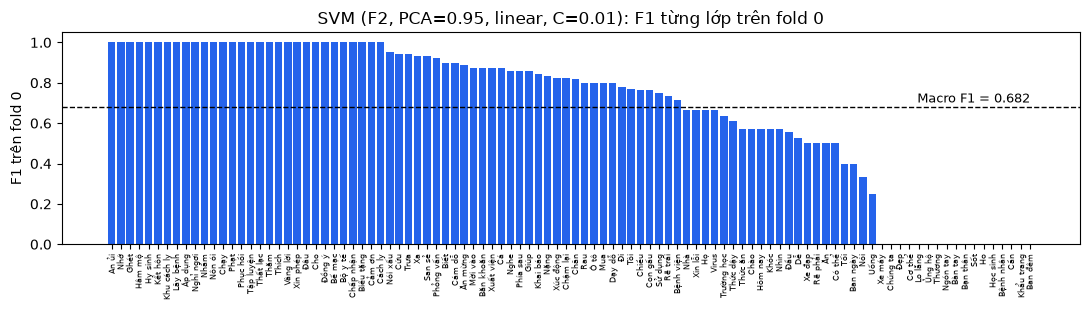

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.2))
s = per_class.sort_values('f1-score', ascending=False)
ax.bar(range(100), s['f1-score'], color='#2563eb', width=0.8)
ax.axhline(val_f1, ls='--', c='k', lw=1)
ax.text(99, val_f1 + 0.02, f'Macro F1 = {val_f1:.3f}', ha='right', fontsize=9)
ax.set_xticks(range(100)); ax.set_xticklabels(s['class'], rotation=90, fontsize=5.5)
ax.set_ylabel('F1 trên fold 0'); ax.set_ylim(0, 1.05)
ax.set_title(f'SVM ({best_desc}): F1 từng lớp trên fold 0')
fig.tight_layout(); fig.savefig(OUT / 'svm_fold0_per_class_f1.png', dpi=150, bbox_inches='tight'); plt.show()

## 6. Huấn luyện lại trên cả 2.772 video và ghi file nộp

Sau khi đã có con số đánh giá trên fold 0, mô hình nộp bài được huấn luyện lại với **cùng cấu hình** trên toàn bộ tập train sạch: thêm 555 video, lớp ít nhất tăng từ 4 lên 5 video.

File nộp có cột `video_name,label`; nhãn lấy từ `label_names.json` nên ở đúng dạng Unicode NFD như `label_mapping.pkl`. AIChallenge chấm trên tập **private test** và đọc file tên `cv_submission.csv` trong file zip, nên dự đoán private được đóng gói sẵn thành `svm_submission.zip`. Dự đoán public test được giữ lại để kiểm tra.

**Kiểm tra phụ:** 156 video public test giống hệt video trong train. Mô hình đã học chính các video đó, nên phải đoán đúng gần hết; nếu không thì có lỗi lệch thứ tự dòng giữa đặc trưng và manifest. Phép kiểm tra này chỉ để phát hiện lỗi, dự đoán **không** bị thay bằng nhãn train.

In [9]:
t0 = time.time()
final_pipe = make_pipeline(best_params).fit(X[best.feature], y)
print(f'Huấn luyện lại trên {len(y)} video trong {time.time() - t0:.0f}s',
      '| số thành phần PCA:', final_pipe.named_steps['pca'].n_components_)

submissions = {}
for split, fname in [('public_test', 'feat_public.npy'), ('private_test', 'feat_private.npy')]:
    rows_ = test_manifest[test_manifest.split == split].reset_index(drop=True)
    F = np.load(FEAT_DIR / fname).astype(np.float32)
    assert len(F) == len(rows_), (split, F.shape, len(rows_))
    pred = final_pipe.predict(pool(F, best.feature))
    sub = pd.DataFrame({'video_name': rows_.file, 'label': [label_names[i] for i in pred]})
    expected = {'public_test': 1630, 'private_test': 2859}[split]
    if not os.environ.get('LIMIT'):
        assert len(sub) == expected, (split, len(sub))
    assert sub.video_name.is_unique
    assert set(sub.label) <= set(label_names)
    assert all(unicodedata.normalize('NFD', s) == s for s in sub.label)
    name = 'svm_public.csv' if split == 'public_test' else 'svm_private.csv'
    sub.to_csv(OUT / name, index=False, encoding='utf-8')
    submissions[split] = (rows_, pred)
    print(f'{name}: {len(sub)} dòng, {sub.label.nunique()} lớp được dự đoán')

rows_pub, pred_pub = submissions['public_test']
md5_label = dict(zip(manifest.md5, manifest.label_idx))
dup = rows_pub.md5.map(md5_label)
mask = dup.notna().values
if mask.sum():
    agree = (pred_pub[mask] == dup[mask].astype(int).values).mean()
    print(f'Kiểm tra phụ: {mask.sum()} video public trùng train, đoán đúng nhãn train {agree:.1%}')
    if agree < 0.5:
        print('CẢNH BÁO: tỉ lệ thấp bất thường – kiểm tra thứ tự dòng của đặc trưng test.')

with zipfile.ZipFile(OUT / 'svm_submission.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    z.write(OUT / 'svm_private.csv', arcname='cv_submission.csv')
print('File nộp: svm_submission.zip (chứa cv_submission.csv)')
pd.read_csv(OUT / 'svm_private.csv').head()

Huấn luyện lại trên 2772 video trong 27s | số thành phần PCA: 597
svm_public.csv: 1630 dòng, 99 lớp được dự đoán
svm_private.csv: 2859 dòng, 91 lớp được dự đoán
Kiểm tra phụ: 156 video public trùng train, đoán đúng nhãn train 100.0%
File nộp: svm_submission.zip (chứa cv_submission.csv)


,video_name,label
0,100425.mp4,Thất lạc
1,100599.mp4,Bạn thân
2,101206.mp4,Khóc
3,101640.mp4,Cá
4,101773.mp4,Khóc


## 7. Lưu mô hình, kết quả và log

In [10]:
joblib.dump({'pipeline': final_pipe, 'feature': best.feature, 'pool_fn': 'F1=mean | F2=mean+std | F3=mean of 4 segments',
             'label_names': label_names, 'display_names': display_names, 'params': best_desc,
             'backbone': 'efficientnet_b0', 'T': 16}, OUT / 'svm.joblib')
cv_df.drop(columns='_params').to_csv(OUT / 'cv_results.csv', index=False)
summary = {'best': best_desc, 'feature': best.feature, 'kernel': best.kernel, 'pca': best.pca, 'C': float(best.C),
           'gamma': best.gamma, 'cv_f1_mean': round(float(best.cv_f1_mean), 4),
           'cv_f1_std': round(float(best.cv_f1_std), 4), 'fold0_accuracy': round(float(val_acc), 4),
           'fold0_macro_f1': round(float(val_f1), 4),
           'pca_components_final': int(final_pipe.named_steps['pca'].n_components_),
           'n_configs': int(len(cv_df)), 'quick': QUICK}
json.dump(summary, open(OUT / 'summary.json', 'w'), indent=2, ensure_ascii=False)

if run is not None:
    run.name = f'svm-{best.feature}-{best.kernel}'
    run.config.update({'best_' + k: v for k, v in summary.items() if k in ('feature', 'kernel', 'pca', 'C', 'gamma')},
                      allow_val_change=True)
    run.log({'cv_results': wandb.Table(dataframe=cv_df.drop(columns='_params')),
             'fold0_per_class': wandb.Table(dataframe=per_class),
             'gridsearch_plot': wandb.Image(str(OUT / 'svm_gridsearch.png')),
             'fold0_per_class_plot': wandb.Image(str(OUT / 'svm_fold0_per_class_f1.png'))})
    run.summary.update({'cv_f1': summary['cv_f1_mean'], 'val_macro_f1': summary['fold0_macro_f1'],
                        'val_accuracy': summary['fold0_accuracy']})
    run.finish()

print(json.dumps(summary, indent=2, ensure_ascii=False))
for p in sorted(q for q in OUT.iterdir() if not q.name.startswith('.')):
    print(f'{p.name:28s}', 'thư mục' if p.is_dir() else f'{p.stat().st_size / 1e6:.2f} MB')

{
  "best": "F2, PCA=0.95, linear, C=0.01",
  "feature": "F2",
  "kernel": "linear",
  "pca": "0.95",
  "C": 0.01,
  "gamma": "-",
  "cv_f1_mean": 0.6792,
  "cv_f1_std": 0.0078,
  "fold0_accuracy": 0.809,
  "fold0_macro_f1": 0.6823,
  "pca_components_final": 597,
  "n_configs": 36,
  "quick": false
}
cv_results.csv               0.00 MB
fold0_report.csv             0.00 MB
summary.json                 0.00 MB
svm.joblib                   6.68 MB
svm_fold0_per_class_f1.png   0.07 MB
svm_gridsearch.png           0.06 MB
svm_private.csv              0.06 MB
svm_public.csv               0.03 MB
svm_submission.zip           0.02 MB
wandb                        thư mục


## 8. Kết quả trên AIChallenge

| Đánh giá | Dữ liệu | Macro F1 |
|---|---|---|
| Cross-validation 4 lần | fold 1–4 | 0,679 |
| Đánh giá một lần | fold 0 | 0,682 |
| Leaderboard AIChallenge | private test (2.859 video) | **0,297** |

Điểm trên tập private thấp hơn nhiều so với fold 0. Định dạng file nộp không có lỗi (156 video public trùng train đều được đoán đúng). Phân bố dự đoán bên dưới cho thấy mô hình dồn nhiều video vào một số ít lớp và bỏ trống một số lớp. Điều này gợi ý rằng video test khác video train: có thể do người ký hiệu, góc quay hoặc bối cảnh khác. Khi chia 5 fold ngẫu nhiên, video của cùng một người có thể nằm ở cả phần train lẫn phần kiểm tra, nên điểm CV và fold 0 phản ánh khả năng trên video giống train hơn là trên video mới.

In [11]:
pred_priv = submissions['private_test'][1]
counts = pd.Series(pred_priv).value_counts()
train_counts = pd.Series(y).value_counts()
missing = sorted(set(range(100)) - set(counts.index))
print(f'Private test: {len(pred_priv)} video, {len(counts)}/100 lớp được dự đoán '
      f'(nếu chia đều thì khoảng {len(pred_priv) / 100:.0f} video/lớp)')
print('Lớp không được dự đoán lần nào:', ', '.join(display_names[i] for i in missing))
pd.DataFrame({'lớp': [display_names[i] for i in counts.index[:10]],
              'số lần dự đoán (private)': counts.values[:10],
              'số video train': train_counts.reindex(counts.index[:10]).values})

Private test: 2859 video, 91/100 lớp được dự đoán (nếu chia đều thì khoảng 29 video/lớp)
Lớp không được dự đoán lần nào: Ban đêm, Chấp nhận, Chúng ta, Kết hôn, Ngón tay, Phỏng vấn, Thích, Ủng hộ, Virus


,lớp,số lần dự đoán (private),số video train
0,Nặng,147,34
1,Nghỉ ngơi,117,49
2,Tôi,109,36
3,Cá,105,41
4,Ăn,97,40
5,Khóc,95,45
6,Chào,92,22
7,Băn khoăn,89,43
8,Phía sau,89,49
9,Xa,65,42
